In [3]:
import pandas as pd
import seaborn as sns

In [5]:
insurance_data = pd.read_csv("insurance.csv");

In [5]:
insurance_data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


<Axes: xlabel='bmi', ylabel='charges'>

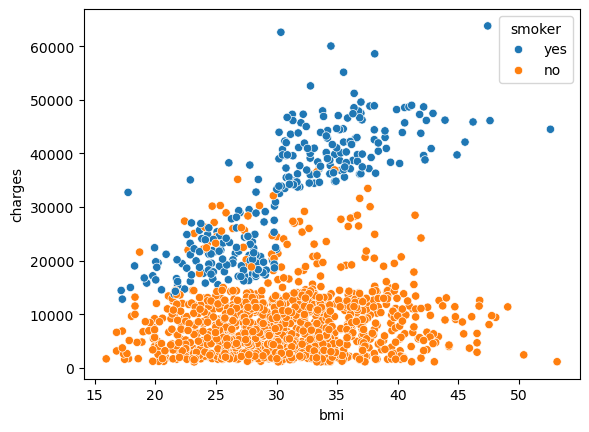

In [7]:
# visulization
sns.scatterplot(x=insurance_data["bmi"], y=insurance_data["charges"], hue=insurance_data['smoker'])

In [31]:
# determining input and output

X = insurance_data.drop(columns=["charges", "region"]);
y = insurance_data['charges'];

In [32]:
X.head()

,age,sex,bmi,children,smoker
0,19,female,27.900,0,yes
1,18,male,33.770,1,no
2,28,male,33.000,3,no
3,33,male,22.705,0,no
4,32,male,28.880,0,no


In [33]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [34]:
# mapping (gender and smoker)

X["sex"] = X['sex'].map({"male": 1, "female": 0});
X['smoker'] = X['smoker'].map({"yes": 1, "no": 0});

In [35]:
X.head()

,age,sex,bmi,children,smoker
0,19,0,27.900,0,1
1,18,1,33.770,1,0
2,28,1,33.000,3,0
3,33,1,22.705,0,0
4,32,1,28.880,0,0


In [37]:
# Split train and test data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [40]:
# Train model

from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train, y_train);

In [41]:
# Predict

pred_y = model.predict(X_test);

In [43]:
pred_y


array([ 8554.81711589,  6973.58746745, 36798.60416104,  9417.88282303,
       26871.68031081, 11097.38383938,   145.27608963, 16746.1683771 ,
         747.53414191, 11153.67590722, 28518.15016561,  9292.18345421,
        5460.51975119, 38510.48013003, 40359.30938604, 37223.40538064,
       15316.56711945, 36047.50032223,  9326.29049907, 31400.1559532 ,
        4269.64414373, 10464.66374097,  2719.9260555 ,  6579.53742551,
       11232.00255515, 12472.06793446, 14807.11281089,  6066.19283362,
        9535.69029723,  2377.6983797 ,  9475.05690885, 12963.23366722,
        4706.09057393,  3414.674504  ,  4815.64981654, 12484.17176954,
        2359.13614479,  9161.02061228, 33238.67621442, 32743.41702445,
        4274.58967205,  4229.5442107 , 14435.36485176, 11384.66898976,
        8925.70468583, 12480.09178788,  5154.45787816,  3554.10047649,
       35649.60942684,  9276.25523701, 15971.35991397,  2552.75200479,
       12162.99980138,  1062.65132285, 13551.43771934, 12103.65505529,
      

In [44]:
y_test


764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64

In [49]:
# test score

from sklearn.metrics import r2_score
r2 = r2_score(y_test, pred_y)

print("R-squared value: ", r2);

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - (((1-r2) * (n-1)) / (n - p - 1))
print("Adjusted R-Squared value: ", adjusted_r2);

R-squared value:  0.7811302113434097
Adjusted R-Squared value:  0.7769533069797343


In [48]:
X_test.shape

(268, 5)

In [30]:
X = insurance_data.drop(columns=["charges"]);
y = insurance_data['charges'];

# one hot encoding
X = pd.get_dummies(X, columns=["region"], drop_first=False, dtype=int)

X["sex"] = X['sex'].map({"male": 1, "female": 0});
X['smoker'] = X['smoker'].map({"yes": 1, "no": 0});

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train, y_train);

y_pred = model.predict(X_test);

In [33]:
# with one hot encoding

from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)

print("R-squared value: ", r2);

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - (((1-r2) * (n-1)) / (n - p - 1))
print("Adjusted R-Squared value: ", adjusted_r2);

R-squared value:  0.7835929767120723
Adjusted R-Squared value:  0.7760438945043538


In [29]:
X.head()

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,0,0,0,1
1,18,1,33.770,1,0,0,0,1,0
2,28,1,33.000,3,0,0,0,1,0
3,33,1,22.705,0,0,0,1,0,0
4,32,1,28.880,0,0,0,1,0,0


In [34]:
X = insurance_data.drop(columns=["charges"]);
y = insurance_data['charges'];

# one hot encoding
X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X['sex'].map({"male": 1, "female": 0});
X['smoker'] = X['smoker'].map({"yes": 1, "no": 0});

In [35]:
X

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,0,0,1
1,18,1,33.770,1,0,0,1,0
2,28,1,33.000,3,0,0,1,0
3,33,1,22.705,0,0,1,0,0
4,32,1,28.880,0,0,1,0,0
...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,0,0
1334,18,0,31.920,0,0,0,0,0
1335,18,0,36.850,0,0,0,1,0
1336,21,0,25.800,0,0,0,0,1


In [36]:
# with dummy variable trap

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train, y_train);

y_pred = model.predict(X_test);

In [37]:

from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)

print("R-squared value: ", r2);

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - (((1-r2) * (n-1)) / (n - p - 1))
print("Adjusted R-Squared value: ", adjusted_r2);


R-squared value:  0.7835929767120724
Adjusted R-Squared value:  0.7769085898923681


<Axes: >

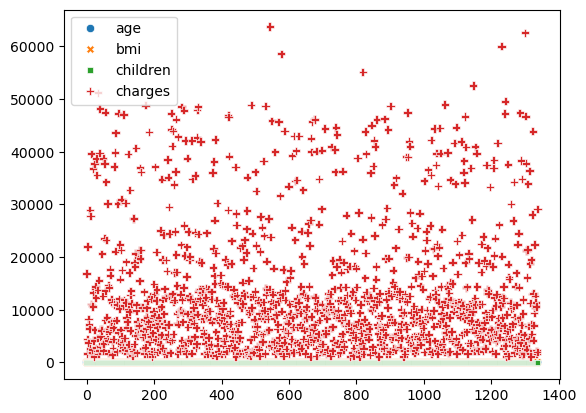

In [6]:
sns.scatterplot(insurance_data)

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = insurance_data.drop(columns=["charges", "region"]);
y = insurance_data['charges'];

X_train, X_test, y_train, y_test = train_test_split(X, y)

model = LinearRegression()
